## Réalisé par : Amina Abbar, Hiba Hanahoum et Alae Abdelouahab
## Master : SNIA

# Notebook 1 - Pipeline ETL & Analyse Exploratoire
## Projet : Classification multi-classes de la santé fœtale (CTG)

**Dataset :** `fetal_health.csv` - Cardiotocographies (CTG) annotées par des obstétriciens experts.

**Lien :** https://www.kaggle.com/datasets/andrewmvd/fetal-health-classification

**Objectif de ce notebook :** mettre en place la chaîne **ETL (Extract - Transform - Load)** complète qui transformera les données brutes en structures (`X_train`, `X_test`, `y_train`, `y_test`) directement exploitables par nos modèles de classification.

### Plan du notebook

1. **EXTRACT** - Découverte brute des données
2. **DATA QUALITY & EDA** - Inspection visuelle guidant les décisions de nettoyage
3. **TRANSFORM** - Nettoyage raisonné et préparation des données
4. **LOAD** - Persistance des structures finales pour le Notebook 2


##  1. SECTION EXTRACT 


In [1]:
# --- Imports nécessaires pour l'ensemble du notebook ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Configuration esthétique des graphiques
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# --- EXTRACT : chargement brut du fichier source ---
df = pd.read_csv("data/fetal_health.csv")

print(f"Dimensions du jeu de données : {df.shape[0]} lignes x {df.shape[1]} colonnes")


Dimensions du jeu de données : 2126 lignes x 22 colonnes


In [2]:
# Aperçu des 5 premières observations
df.head()


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [3]:
# Structure technique : types de données, mémoire, valeurs non-nulles déclarées
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability             

In [4]:
# Photographie statistique globale du jeu de données
df.describe().T


,count,mean,std,min,25%,50%,75%,max
baseline value,2126.0,133.303857,9.840844,106.0,126.000,133.000,140.000,160.000
accelerations,2126.0,0.003178,0.003866,0.0,0.000,0.002,0.006,0.019
fetal_movement,2126.0,0.009481,0.046666,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2126.0,0.004366,0.002946,0.0,0.002,0.004,0.007,0.015
light_decelerations,2126.0,0.001889,0.002960,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2126.0,0.000003,0.000057,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2126.0,0.000159,0.000590,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2126.0,46.990122,17.192814,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2126.0,1.332785,0.883241,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2126.0,9.846660,18.396880,0.0,0.000,0.000,11.000,91.000


###  Constat n°1 : Première lecture des données

L'inspection brute révèle plusieurs éléments structurants pour la suite de notre travail :

- **22 colonnes au total**, dont **21 variables explicatives** (features cardiotocographiques) et **1 variable cible** : `fetal_health`.
- **Homogénéité des types** : l'intégralité des colonnes est de type `float64`, y compris la cible. C'est inhabituel pour une variable catégorielle, cela signifie que `fetal_health` est en réalité un **entier encodé en flottant** (valeurs 1.0, 2.0, 3.0), ce qui devra être corrigé lors de l'étape *Transform*.
- **Aucune colonne `object`** : pas de variable textuelle ou catégorielle brute à encoder (pas de One-Hot Encoding nécessaire), ce qui simplifie grandement le pipeline, toutes les features sont déjà numériques.
- **`.info()` ne signale aucune valeur non-nulle manquante apparente** (2126 entrées non-nulles sur 2126 pour chaque colonne), mais ce point sera vérifié plus rigoureusement avec `.isnull().sum()` dans la section suivante, `.info()` seul ne suffit jamais à garantir l'absence de données manquantes encodées sous une autre forme (ex. valeurs sentinelles comme -1 ou 999).
- **Échelles très hétérogènes** entre les features (visible via `.describe()`) : certaines variables comme `accelerations` ou `uterine_contractions` varient entre 0 et 0.02, tandis que `histogram_width` ou `baseline value` évoluent sur des échelles de dizaines à centaines. Cette hétérogénéité confirme qu'une étape de **mise à l'échelle (Feature Scaling)** sera indispensable avant tout entraînement de modèle sensible aux distances ou aux gradients.

Ces premiers constats orientent déjà notre stratégie de nettoyage : nous savons qu'il faudra **recoder la cible**, **vérifier finement les valeurs manquantes**, et **standardiser les features**. Mais avant d'agir, poursuivons l'inspection, notamment celle de la variable cible elle-même.


##  2. SECTION DATA QUALITY & EDA 

C'est la phase centrale de notre démarche exploratoire. Plutôt que d'appliquer des recettes de nettoyage standard, nous laissons les graphiques et les statistiques **guider nos décisions**. Chaque visualisation produite ici a une finalité décisionnelle directe sur l'étape *Transform* qui suivra.


### Graphe 1 : Distribution de la variable cible `fetal_health`

Avant d'examiner les features, il est primordial de comprendre la structure de ce que l'on cherche à prédire. 


C:\Users\HP\AppData\Local\Temp\ipykernel_10504\2546721242.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([class_labels[float(t.get_text())] for t in ax.get_xticklabels()])


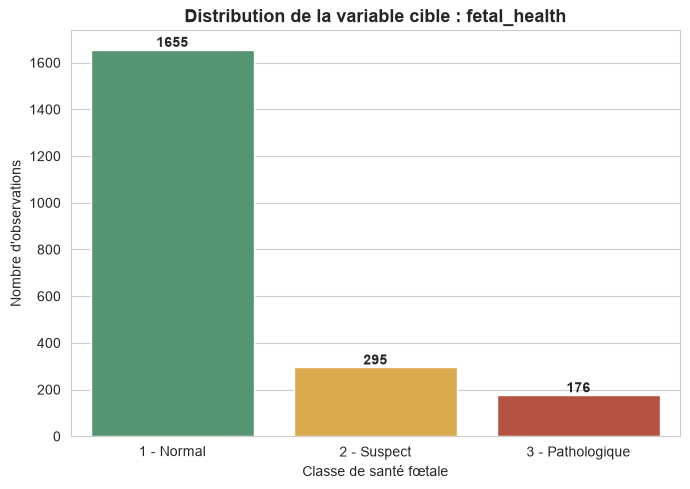

Répartition des classes (%) :
fetal_health
1.0    77.85
2.0    13.88
3.0     8.28
Name: proportion, dtype: float64


In [5]:
# --- Graphe 1 : Distribution de la cible fetal_health ---
fig, ax = plt.subplots(figsize=(7, 5))

# Comptage des occurrences par classe avec annotation des labels métiers
class_labels = {1.0: "1 - Normal", 2.0: "2 - Suspect", 3.0: "3 - Pathologique"}

sns.countplot(
    data=df,
    x="fetal_health",
    hue="fetal_health",
    palette=["#4C9F70", "#F2B134", "#C84630"],
    legend=False,
    ax=ax
)

ax.set_xticklabels([class_labels[float(t.get_text())] for t in ax.get_xticklabels()])
ax.set_title("Distribution de la variable cible : fetal_health", fontsize=13, fontweight="bold")
ax.set_xlabel("Classe de santé fœtale")
ax.set_ylabel("Nombre d'observations")

# Annotation des effectifs sur chaque barre
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

# Répartition exacte en pourcentage
print("Répartition des classes (%) :")
print((df["fetal_health"].value_counts(normalize=True).sort_index() * 100).round(2))


###  Constat n°2 : Un déséquilibre de classes marqué

Le graphique est sans ambiguïté : la classe **1 (Normal)** représente **1655 observations (77.85 %)**, contre seulement **295 (13.88 %)** pour la classe **2 (Suspect)** et **176 (8.28 %)** pour la classe **3 (Pathologique)**.

**Conséquence méthodologique directe :** ce déséquilibre n'est pas un simple détail descriptif — il **conditionne notre stratégie de découpage Train/Test**. Un découpage aléatoire classique (`train_test_split` sans contrainte) risquerait, par simple effet du hasard, de sous-représenter encore davantage la classe minoritaire 3 (déjà rare avec seulement 176 individus) dans l'un des deux sous-ensembles — particulièrement problématique sur le jeu de test, où une représentation insuffisante des classes rares biaiserait l'évaluation finale du modèle.

**Décision prise dès maintenant :** nous utiliserons l'argument `stratify=y` lors du split, afin de **préserver la même proportion des trois classes** dans `y_train` et `y_test` que dans le jeu de données original. Cette précaution est d'autant plus critique pour les classes 2 et 3 dont l'effectif est déjà restreint.

Ce déséquilibre devra également être gardé en mémoire pour le Notebook 2 (choix des métriques d'évaluation — F1-score macro/pondéré plutôt que l'accuracy seule — et éventuellement des stratégies de rééquilibrage comme SMOTE ou des poids de classes).


### Graphe 2 : Qualité intrinsèque des données : doublons et valeurs manquantes

Après avoir caractérisé la cible, nous inspectons la **qualité brute** du jeu de données.


In [6]:
# --- Recherche des doublons ---
nb_doublons = df.duplicated().sum()
print(f"Nombre de lignes strictement dupliquées : {nb_doublons}")
print(f"Proportion du dataset concernée : {nb_doublons / len(df) * 100:.2f} %")

# Aperçu des lignes dupliquées (hors première occurrence)
print("\nAperçu de quelques lignes dupliquées détectées :")
df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(10)


Nombre de lignes strictement dupliquées : 13
Proportion du dataset concernée : 0.61 %

Aperçu de quelques lignes dupliquées détectées :


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
1112,122.0,0.000,0.000,0.0,0.0,0.0,0.0,19.0,1.9,0.0,...,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
1113,122.0,0.000,0.000,0.0,0.0,0.0,0.0,19.0,1.9,0.0,...,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
1114,122.0,0.000,0.000,0.0,0.0,0.0,0.0,19.0,1.9,0.0,...,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
1115,122.0,0.000,0.000,0.0,0.0,0.0,0.0,19.0,1.9,0.0,...,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
233,123.0,0.000,0.000,0.0,0.0,0.0,0.0,49.0,0.8,7.0,...,63.0,137.0,2.0,0.0,129.0,127.0,129.0,2.0,1.0,1.0
234,123.0,0.000,0.000,0.0,0.0,0.0,0.0,49.0,0.8,7.0,...,63.0,137.0,2.0,0.0,129.0,127.0,129.0,2.0,1.0,1.0
229,123.0,0.003,0.003,0.0,0.0,0.0,0.0,52.0,0.8,2.0,...,50.0,140.0,7.0,0.0,129.0,128.0,130.0,4.0,1.0,1.0
787,123.0,0.003,0.003,0.0,0.0,0.0,0.0,52.0,0.8,2.0,...,50.0,140.0,7.0,0.0,129.0,128.0,130.0,4.0,1.0,1.0
790,123.0,0.003,0.004,0.0,0.0,0.0,0.0,50.0,0.9,4.0,...,58.0,140.0,7.0,0.0,129.0,128.0,130.0,5.0,1.0,1.0
791,123.0,0.003,0.004,0.0,0.0,0.0,0.0,50.0,0.9,4.0,...,58.0,140.0,7.0,0.0,129.0,128.0,130.0,5.0,1.0,1.0


In [7]:
# --- Recherche des valeurs manquantes ---
valeurs_manquantes = df.isnull().sum()
print("Valeurs manquantes par colonne :")
print(valeurs_manquantes[valeurs_manquantes > 0] if valeurs_manquantes.sum() > 0 else "Aucune valeur manquante détectée.")
print(f"\nTotal de valeurs manquantes sur l'ensemble du dataset : {valeurs_manquantes.sum()}")


Valeurs manquantes par colonne :
Aucune valeur manquante détectée.

Total de valeurs manquantes sur l'ensemble du dataset : 0


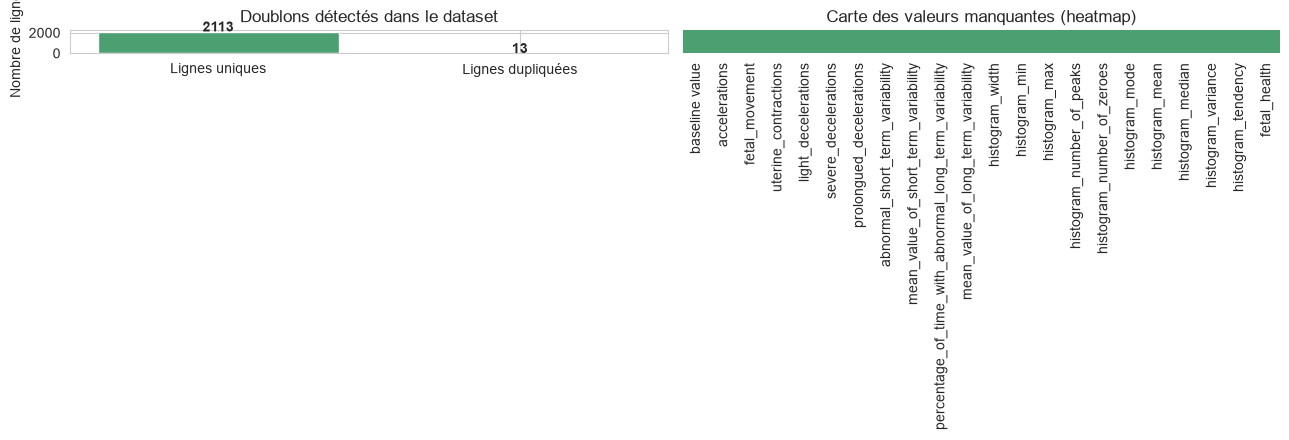

In [8]:
# --- Visualisation synthétique de la qualité du dataset ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Sous-graphe 1 : doublons vs lignes uniques
axes[0].bar(
    ["Lignes uniques", "Lignes dupliquées"],
    [len(df) - nb_doublons, nb_doublons],
    color=["#4C9F70", "#C84630"]
)
axes[0].set_title("Doublons détectés dans le dataset")
axes[0].set_ylabel("Nombre de lignes")
for i, v in enumerate([len(df) - nb_doublons, nb_doublons]):
    axes[0].text(i, v + 10, str(v), ha="center", fontweight="bold")

# Sous-graphe 2 : carte des valeurs manquantes (heatmap)
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap=["#4C9F70"], ax=axes[1])
axes[1].set_title("Carte des valeurs manquantes (heatmap)")

plt.tight_layout()
plt.show()


###  Constat n°3 : Doublons présents, données complètes

Deux observations distinctes émergent de cette inspection :

1. **Valeurs manquantes : aucune.** `.isnull().sum()` confirme l'absence totale de `NaN` sur les 2126 observations et 22 colonnes. Le dataset est donc **complet** — aucune stratégie d'imputation (moyenne, médiane, KNN-imputer...) ne sera nécessaire dans la section *Transform*. C'est une bonne nouvelle qui simplifie le pipeline.

2. **Doublons : 13 lignes strictement identiques détectées.** Bien que cela ne représente qu'environ 0.6 % du dataset, leur présence n'est pas anodine. Des observations cardiotocographiques rigoureusement identiques sur 22 variables (y compris la cible) sont statistiquement suspectes — elles proviennent très probablement d'une erreur d'export ou d'une duplication lors de la collecte, et non d'un hasard clinique légitime.

**Décision prise :** ces 13 doublons seront supprimés lors de l'étape *Transform*. La justification détaillée de ce choix (notamment son impact sur les modèles à base d'arbres) sera développée dans la section correspondante, juste avant son application.


### Graphe 3 : Distribution des features clés selon les classes de santé fœtale

Nous terminons notre inspection visuelle par l'étude de la **relation entre quelques variables explicatives critiques et la cible**. L'objectif est double : vérifier que ces variables discriminent visuellement bien les classes (ce qui valide leur pertinence clinique et statistique), et repérer la présence de **valeurs aberrantes (outliers)** qui pourraient nécessiter une attention particulière.

Nous sélectionnons trois variables aux significations cliniques fortes :
- `baseline value` : fréquence cardiaque fœtale de référence (battements par minute),
- `accelerations` : nombre d'accélérations du rythme cardiaque par seconde (signe généralement rassurant),
- `prolongued_decelerations` : décélérations prolongées du rythme cardiaque (signe de détresse fœtale potentielle).


C:\Users\HP\AppData\Local\Temp\ipykernel_10504\3983644937.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)
C:\Users\HP\AppData\Local\Temp\ipykernel_10504\3983644937.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)
C:\Users\HP\AppData\Local\Temp\ipykernel_10504\3983644937.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)


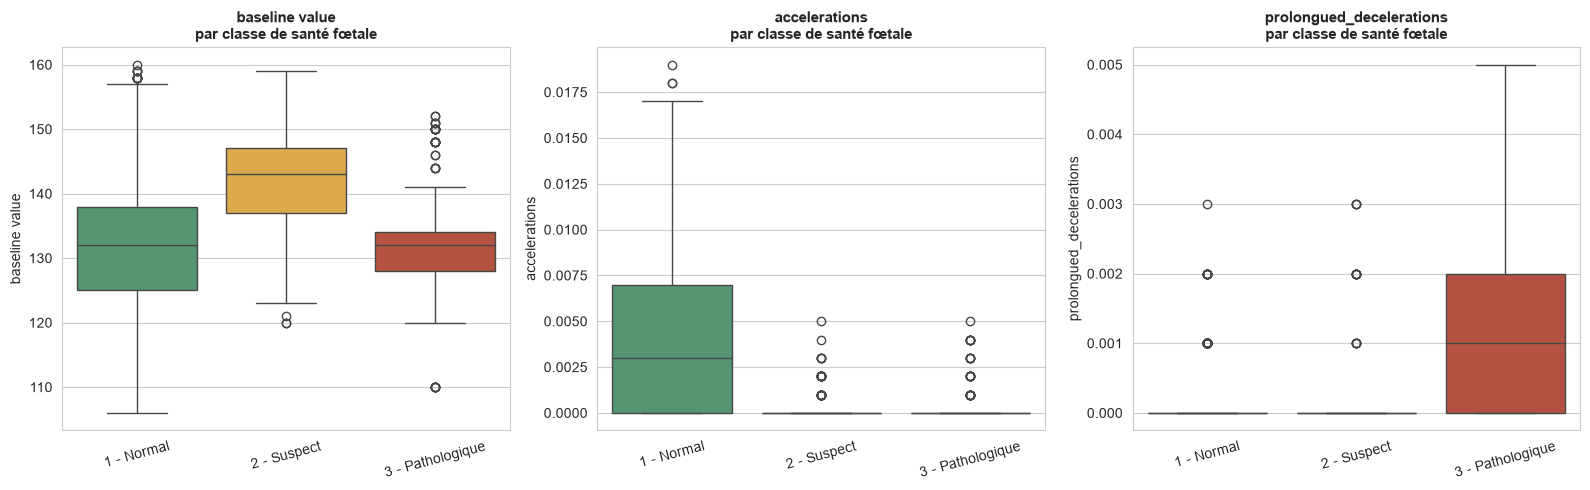

In [9]:
# --- Graphe 3 : Boxplots des features clés selon la classe de santé fœtale ---
features_cles = ["baseline value", "accelerations", "prolongued_decelerations"]
palette_classes = ["#4C9F70", "#F2B134", "#C84630"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features_cles):
    sns.boxplot(
        data=df,
        x="fetal_health",
        y=feature,
        hue="fetal_health",
        palette=palette_classes,
        legend=False,
        ax=ax
    )
    ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)
    ax.set_title(f"{feature}\npar classe de santé fœtale", fontsize=11, fontweight="bold")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_10504\4020554672.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)
C:\Users\HP\AppData\Local\Temp\ipykernel_10504\4020554672.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)
C:\Users\HP\AppData\Local\Temp\ipykernel_10504\4020554672.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)


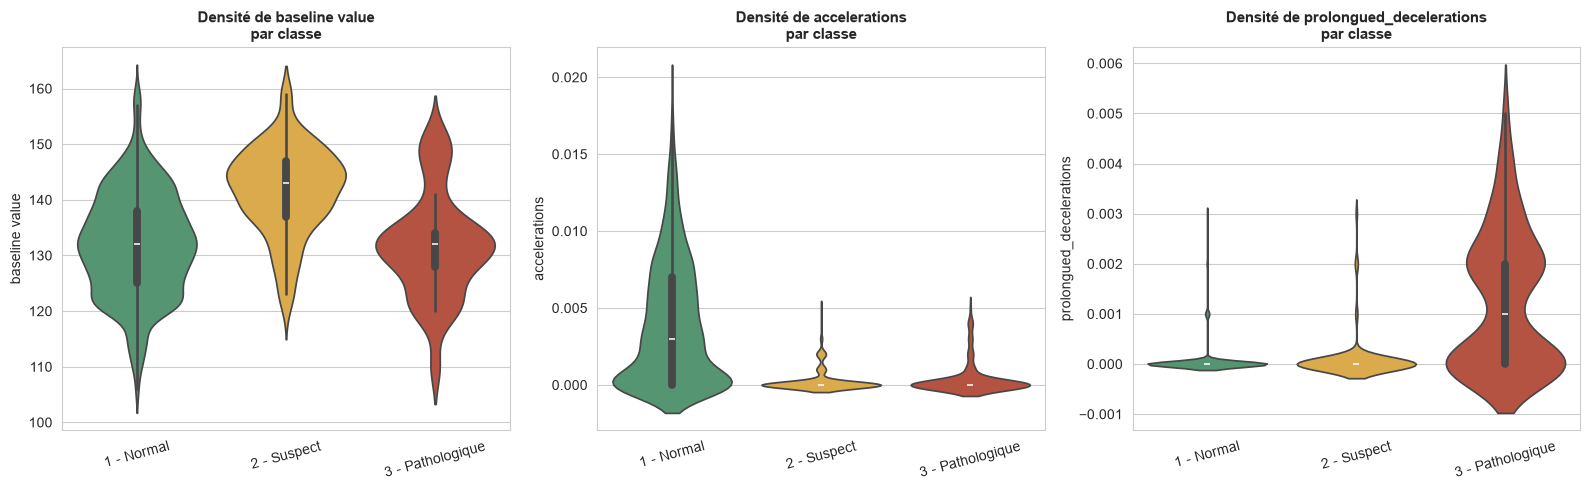

In [10]:
# --- Complément : violinplot pour observer la densité de distribution (et non seulement les quartiles) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features_cles):
    sns.violinplot(
        data=df,
        x="fetal_health",
        y=feature,
        hue="fetal_health",
        palette=palette_classes,
        legend=False,
        ax=ax
    )
    ax.set_xticklabels(["1 - Normal", "2 - Suspect", "3 - Pathologique"], rotation=15)
    ax.set_title(f"Densité de {feature}\npar classe", fontsize=11, fontweight="bold")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()


###  Constat n°4 : Des outliers cliniquement plausibles, pas des erreurs

L'observation conjointe des boxplots et violinplots révèle deux enseignements majeurs :

- **Pouvoir discriminant confirmé.** Les trois variables sélectionnées séparent visuellement bien les classes : `prolongued_decelerations` est quasiment nulle pour la classe 1 (Normal) mais présente des valeurs nettement plus élevées pour la classe 3 (Pathologique), ce qui est cohérent avec la littérature obstétricale — des décélérations prolongées répétées sont un signe d'alerte de souffrance fœtale. De même, `accelerations` tend à être plus présente chez les fœtus en bonne santé (classe 1).

- **De nombreux points aberrants apparaissent sur les boxplots**, en particulier pour `accelerations` et `prolongued_decelerations`. Cependant, **ces valeurs extrêmes ne sont pas des erreurs de saisie à supprimer** : il s'agit de mesures cardiotocographiques réelles, et les classes minoritaires (Suspect, Pathologique) sont par nature constituées de cas cliniques extrêmes — c'est précisément leur caractère « anormal » qui les rend cliniquement significatifs et qui permet au modèle de les apprendre. Supprimer ces outliers reviendrait à amputer le dataset des informations les plus utiles pour détecter la pathologie, et aggraverait encore le déséquilibre déjà observé sur la classe 3.

**Décision prise :** nous ne supprimons **aucune observation** sur la base de ces outliers. Cette inspection visuelle confirme en revanche, une fois de plus, la nécessité d'une **standardisation (Feature Scaling)**, car les échelles de ces variables sont très différentes (`accelerations` ∈ [0, 0.02] contre `baseline value` ∈ [106, 160]), ce qui pourrait sinon déséquilibrer artificiellement leur poids dans les modèles sensibles aux distances.

---

**Synthèse de notre phase d'inspection (EDA) :** notre démarche exploratoire nous a permis d'identifier précisément quatre actions de nettoyage à mener, et une seule à éviter :

| Décision | Action |
|---|---|
| ✅ Supprimer les 13 doublons détectés | Oui |
| ✅ Stratifier le split Train/Test | Oui (`stratify=y`) |
| ✅ Recoder la cible de [1,2,3] vers [0,1,2] | Oui (requis par XGBoost) |
| ✅ Standardiser les features | Oui (`StandardScaler`) |
| ❌ Supprimer les outliers cliniques | Non — information discriminante essentielle |
| ❌ Imputer des valeurs manquantes | Non nécessaire — dataset complet |

Nous passons maintenant à l'application concrète de ces décisions.


##  3. SECTION TRANSFORM 

Cette section applique, dans l'ordre logique, les quatre transformations identifiées lors de notre phase d'inspection.

### 3.1 - Suppression des doublons

**Pourquoi les doublons faussent particulièrement les modèles à base d'arbres :**

Les algorithmes comme les arbres de décision, Random Forest ou XGBoost construisent leurs règles de décision en cherchant les seuils qui maximisent la séparation des classes (via le gain d'information ou l'indice de Gini). Une ligne dupliquée n'apporte **aucune information nouvelle**, mais elle est comptée **deux fois** dans le calcul des statistiques internes de l'algorithme (impuretés de nœuds, fréquences de classe). Cela revient à **sur-pondérer artificiellement** l'observation concernée, comme si elle représentait deux individus distincts. À petite échelle (13 lignes sur 2126), l'effet est limité, mais il introduit un biais évitable et constitue une mauvaise pratique méthodologique — d'autant plus risqué si certains de ces doublons se retrouvent répartis entre le Train et le Test, ce qui provoquerait une **fuite de données (data leakage)** : le modèle serait alors évalué sur une observation qu'il a déjà vue à l'identique pendant l'entraînement, gonflant artificiellement les métriques de performance.

Nous supprimons donc ces lignes **avant** le split Train/Test, précisément pour éviter ce risque de fuite.


In [11]:
# --- Suppression des doublons identifiés lors de l'inspection ---
print(f"Nombre de lignes avant nettoyage : {len(df)}")

df_clean = df.drop_duplicates().reset_index(drop=True)

print(f"Nombre de lignes après suppression des doublons : {len(df_clean)}")
print(f"Lignes supprimées : {len(df) - len(df_clean)}")


Nombre de lignes avant nettoyage : 2126
Nombre de lignes après suppression des doublons : 2113
Lignes supprimées : 13


### 3.2 - Séparation features / cible et split stratifié

Nous séparons maintenant le dataset nettoyé en matrice de caractéristiques $X$ et vecteur cible $y$, puis nous appliquons un découpage Train/Test. Comme établi lors de notre EDA, l'argument **`stratify=y` est indispensable** : il garantit que la proportion des trois classes (77.85 % / 13.88 % / 8.28 % environ) est respectée à l'identique dans `X_train`/`y_train` et `X_test`/`y_test`, évitant qu'un tirage aléatoire malheureux ne prive le jeu de test de représentants suffisants de la classe 3 (Pathologique), déjà minoritaire.


In [12]:
# --- Séparation features (X) / cible (y) ---
X = df_clean.drop(columns=["fetal_health"])
y = df_clean["fetal_health"]

print(f"Dimensions de X : {X.shape}")
print(f"Dimensions de y : {y.shape}")


Dimensions de X : (2113, 21)
Dimensions de y : (2113,)


In [13]:
# --- Split Train/Test STRATIFIÉ (préserve la répartition des 3 classes) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # crucial : conserve les proportions de classes dans Train et Test
)

print(f"Taille du Train : {X_train.shape[0]} observations")
print(f"Taille du Test  : {X_test.shape[0]} observations")

print("\nVérification du respect de la stratification (%) :")
print("Train :")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))
print("\nTest :")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))


Taille du Train : 1690 observations
Taille du Test  : 423 observations

Vérification du respect de la stratification (%) :
Train :
fetal_health
1.0    77.87
2.0    13.85
3.0     8.28
Name: proportion, dtype: float64

Test :
fetal_health
1.0    78.01
2.0    13.71
3.0     8.27
Name: proportion, dtype: float64


###  Vérification post-split

Les pourcentages affichés ci-dessus pour `y_train` et `y_test` doivent être quasi identiques à ceux observés lors de notre EDA initiale (≈ 77.9 % / 13.9 % / 8.3 %). Cette cohérence confirme que la stratification a fonctionné comme attendu et que nos deux sous-ensembles sont représentatifs du dataset complet.


### 3.3 - Encodage strict de la cible (0 à 2)

**Pourquoi ce recodage est obligatoire :** la variable `fetal_health` est actuellement encodée sur les valeurs **{1.0, 2.0, 3.0}**. Certains algorithmes de classification multi-classes — et XGBoost en particulier — exigent que les labels de la cible soient des **entiers consécutifs commençant à 0**. Si l'on tente d'entraîner un modèle XGBoost directement sur des labels {1, 2, 3}, celui-ci lèvera une erreur (`ValueError`) car il interprète les classes comme un intervalle `[0, num_class[` et ne trouve pas de classe 0.

Nous appliquons donc un mapping explicite et documenté :

| Valeur originale | Nouvelle valeur | Signification clinique |
|---|---|---|
| 1.0 | **0** | Normal |
| 2.0 | **1** | Suspect |
| 3.0 | **2** | Pathologique |

Ce mapping est appliqué **après le split**, sur `y_train` et `y_test` séparément, afin de ne jamais perturber la cohérence du découpage stratifié déjà réalisé.


In [14]:
# --- Encodage strict de la cible : {1,2,3} -> {0,1,2} ---
mapping_cible = {1.0: 0, 2.0: 1, 3.0: 2}
noms_classes = ["Normal", "Suspect", "Pathologique"]  # index 0, 1, 2 respectivement

y_train_encoded = y_train.map(mapping_cible).astype(int)
y_test_encoded = y_test.map(mapping_cible).astype(int)

print("Valeurs uniques de y_train après encodage :", sorted(y_train_encoded.unique()))
print("Valeurs uniques de y_test après encodage  :", sorted(y_test_encoded.unique()))

# On remplace définitivement les variables de travail par leur version encodée
y_train = y_train_encoded
y_test = y_test_encoded


Valeurs uniques de y_train après encodage : [np.int64(0), np.int64(1), np.int64(2)]
Valeurs uniques de y_test après encodage  : [np.int64(0), np.int64(1), np.int64(2)]


### 3.4 - Feature Scaling (StandardScaler)

**Règle méthodologique fondamentale, ajustement uniquement sur le Train :** le `StandardScaler` est **ajusté (`fit`) exclusivement sur `X_train`**, puis **appliqué (`transform`)** à la fois sur `X_train` et `X_test`. Ajuster le scaler sur l'ensemble du dataset (avant le split, ou sur Train+Test) provoquerait une **fuite de données (data leakage)** : les statistiques (moyenne, écart-type) du jeu de test contamineraient l'apprentissage, faussant artificiellement l'évaluation finale du modèle. Le jeu de test doit rester un simulacre de données **jamais vues**, y compris au niveau de ses statistiques descriptives.


In [15]:
# --- Feature Scaling : ajustement strict sur le Train uniquement ---
scaler = StandardScaler()

# Fit exclusivement sur X_train
scaler.fit(X_train)

# Transform appliqué à Train ET Test avec les paramètres appris sur le Train
X_train_scaled = pd.DataFrame(
    scaler.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Aperçu de X_train après standardisation (moyenne ≈ 0, écart-type ≈ 1) :")
X_train_scaled.describe().T[["mean", "std"]].round(3).head(10)


Aperçu de X_train après standardisation (moyenne ≈ 0, écart-type ≈ 1) :


,mean,std
baseline value,0.0,1.0
accelerations,-0.0,1.0
fetal_movement,-0.0,1.0
uterine_contractions,-0.0,1.0
light_decelerations,-0.0,1.0
severe_decelerations,-0.0,1.0
prolongued_decelerations,-0.0,1.0
abnormal_short_term_variability,0.0,1.0
mean_value_of_short_term_variability,0.0,1.0
percentage_of_time_with_abnormal_long_term_variability,-0.0,1.0


In [16]:
# On remplace définitivement les structures de travail par leur version standardisée
X_train = X_train_scaled
X_test = X_test_scaled


##  4. SECTION LOAD

Dernière étape de notre chaîne ETL : le **chargement (Load)** des données transformées vers un support de stockage persistant et optimisé, afin que le Notebook 2 (modélisation) puisse les réutiliser directement sans recalculer l'ensemble du pipeline de préparation.

Nous sérialisons l'ensemble des objets nécessaires, `X_train`, `X_test`, `y_train`, `y_test`, le `scaler` ajusté, et les noms des classes, dans un unique fichier binaire au format `pickle`, garantissant rapidité de chargement et fidélité parfaite des types de données (DataFrames, arrays, objets sklearn).


In [17]:
# --- LOAD : sérialisation de l'ensemble des structures finalisées ---
donnees_preparees = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "scaler": scaler,
    "class_names": noms_classes,  # index 0 -> Normal, 1 -> Suspect, 2 -> Pathologique
}

with open("prepared_fetal_data.pkl", "wb") as f:
    pickle.dump(donnees_preparees, f)

print("Fichier 'prepared_fetal_data.pkl' sauvegardé avec succès.")
print(f"Contenu : {list(donnees_preparees.keys())}")


Fichier 'prepared_fetal_data.pkl' sauvegardé avec succès.
Contenu : ['X_train', 'X_test', 'y_train', 'y_test', 'scaler', 'class_names']


In [18]:
# --- Vérification finale : relecture du fichier sauvegardé ---
with open("prepared_fetal_data.pkl", "rb") as f:
    verif = pickle.load(f)

print("Vérification post-sauvegarde :")
print(f"  X_train : {verif['X_train'].shape}")
print(f"  X_test  : {verif['X_test'].shape}")
print(f"  y_train : {verif['y_train'].shape} | classes uniques : {sorted(verif['y_train'].unique())}")
print(f"  y_test  : {verif['y_test'].shape} | classes uniques : {sorted(verif['y_test'].unique())}")
print(f"  scaler  : {type(verif['scaler']).__name__}")
print(f"  class_names : {verif['class_names']}")


Vérification post-sauvegarde :
  X_train : (1690, 21)
  X_test  : (423, 21)
  y_train : (1690,) | classes uniques : [np.int64(0), np.int64(1), np.int64(2)]
  y_test  : (423,) | classes uniques : [np.int64(0), np.int64(1), np.int64(2)]
  scaler  : StandardScaler
  class_names : ['Normal', 'Suspect', 'Pathologique']


##  Conclusion du Notebook 1

Cette démarche exploratoire et itérative nous a permis de transformer un fichier CSV brut en un jeu de données rigoureusement préparé pour la modélisation :

- **Extract** : chargement et première caractérisation de 2126 observations × 22 colonnes, exclusivement numériques.
- **Data Quality & EDA** : mise en évidence d'un **fort déséquilibre de classes** (77.85 % / 13.88 % / 8.28 %), détection de **13 doublons**, confirmation de l'**absence de valeurs manquantes**, et validation visuelle du pouvoir discriminant des features cliniques (avec conservation volontaire des outliers, porteurs d'information clinique).
- **Transform** : suppression des doublons, **split stratifié** Train/Test (80/20), **recodage de la cible** vers {0, 1, 2} pour compatibilité avec XGBoost, et **standardisation** des features ajustée uniquement sur le Train.
- **Load** : persistance de l'ensemble des structures dans `prepared_fetal_data.pkl`, prêtes à être consommées par le Notebook 2 (modélisation et comparaison de classifieurs).

Chaque décision de cette chaîne ETL a été motivée par une observation concrète issue de l'inspection des données, et non par l'application mécanique d'une recette standard — c'est cette traçabilité du raisonnement qui constitue la valeur ajoutée d'une véritable démarche d'Analyse Exploratoire de Données.
